In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np

column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
df = pd.read_csv('IrisData_full.csv', header=None, names=column_names)

X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].values 
y = df['class'].values

In [3]:
def findMinMax(array,col):
    minN,maxN=array[0][col],array[0][col]
    for k in range(1,len(array)):
        if (array[k][col]<minN):
            minN=array[k][col]
        elif (array[k][col]>maxN):
            maxN=array[k][col]
    return [minN,maxN]

def normalize(array,col):
    mins=findMinMax(array,col)
    minN,maxN=mins[0],mins[1]
    for j in range(len(array)):
        array[j][col]=(array[j][col]-minN)/(maxN-minN)
    return 0

X_norm=X.copy()
for i in range(len(X_norm[0])):
    normalize(X_norm,i)

In [31]:
x_learn, x_test, y_learn, y_test = train_test_split(X_norm, y, test_size=0.2, random_state=1) # 1 норм
x_learn = x_learn.tolist()
x_test = x_test.tolist()
y_learn = y_learn.tolist()
y_test = y_test.tolist()
                                                   
print(f"Загальна кількість записів: {len(df)}")     
print(f"Розмір навчальної вибірки: {len(x_learn)}") 
print(f"Розмір тестової вибірки: {len(x_test)}")    

Загальна кількість записів: 150
Розмір навчальної вибірки: 120
Розмір тестової вибірки: 30


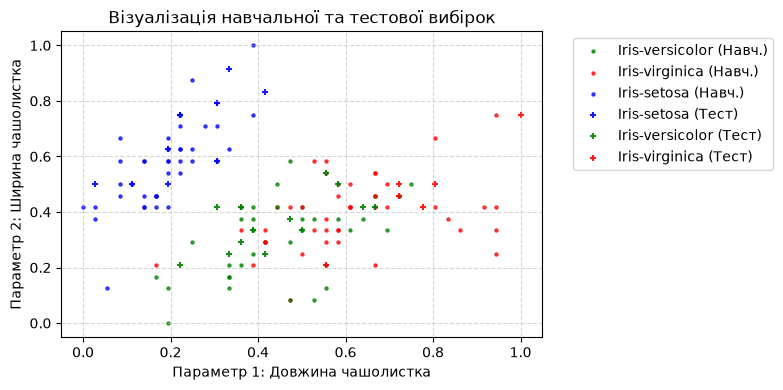

In [32]:
import matplotlib.pyplot as plt

# Словник кольорів для різних видів квітів
# Якщо ваші класи називаються інакше (без 'Iris-'), змініть ключі в словнику
colors = {'Iris-setosa': 'blue', 'Iris-versicolor': 'green', 'Iris-virginica': 'red'}

plt.figure(figsize=(8, 4))

# Змінна для відстеження вже доданих у легенду міток (щоб у легенді не було 150 однакових записів)
added_labels = set()

# 1. Відмальовуємо НАВЧАЛЬНУ вибірку (маркер 'o' - кружечок)
for i in range(len(x_learn)):
    flower_class = y_learn[i]
    # Формуємо назву для легенди
    label_name = f"{flower_class} (Навч.)"
    
    plt.scatter(
        x_learn[i][0],      # X: перша властивість (індекс 0)
        x_learn[i][1],      # Y: друга властивість (індекс 1)
        color=colors.get(flower_class, 'black'), # Шукаємо колір, якщо не знайдено - чорний
        marker='.',         # Кружечок
        s=20,               # Розмір точки
        alpha=0.7,          # Прозорість
        label=label_name if label_name not in added_labels else "" # Додаємо в легенду лише один раз
    )
    added_labels.add(label_name)

# 2. Відмальовуємо ТЕСТОВУ вибірку (маркер 'X' - хрестик)
for i in range(len(x_test)):
    flower_class = y_test[i]
    # Формуємо назву для легенди
    label_name = f"{flower_class} (Тест)"
    
    plt.scatter(
        x_test[i][0],       # X: перша властивість
        x_test[i][1],       # Y: друга властивість
        color=colors.get(flower_class, 'black'),
        marker='+',         # Хрестик
        s=20,               # Розмір робимо трохи більшим, щоб краще було видно
        alpha=0.9,
        label=label_name if label_name not in added_labels else ""
    )
    added_labels.add(label_name)

# Налаштування зовнішнього вигляду графіка
plt.title('Візуалізація навчальної та тестової вибірок')
plt.xlabel('Параметр 1: Довжина чашолистка')
plt.ylabel('Параметр 2: Ширина чашолистка')

# Виводимо легенду за межами графіка праворуч
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Показуємо результат
plt.show()

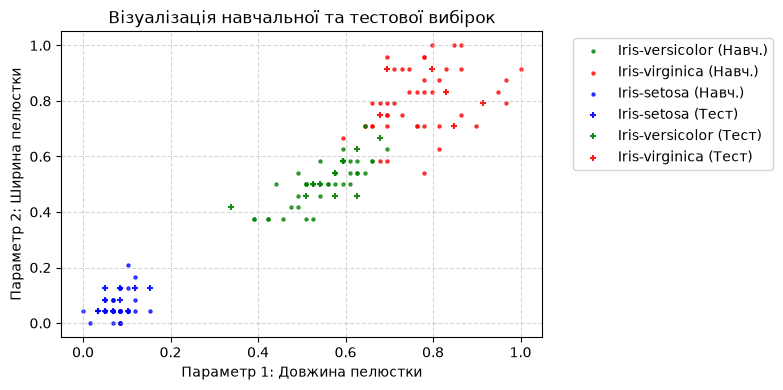

In [33]:
import matplotlib.pyplot as plt

# Словник кольорів для різних видів квітів
# Якщо ваші класи називаються інакше (без 'Iris-'), змініть ключі в словнику
colors = {'Iris-setosa': 'blue', 'Iris-versicolor': 'green', 'Iris-virginica': 'red'}

plt.figure(figsize=(8, 4))

# Змінна для відстеження вже доданих у легенду міток (щоб у легенді не було 150 однакових записів)
added_labels = set()

# 1. Відмальовуємо НАВЧАЛЬНУ вибірку (маркер 'o' - кружечок)
for i in range(len(x_learn)):
    flower_class = y_learn[i]
    # Формуємо назву для легенди
    label_name = f"{flower_class} (Навч.)"
    
    plt.scatter(
        x_learn[i][2],      # X: перша властивість (індекс 0)
        x_learn[i][3],      # Y: друга властивість (індекс 1)
        color=colors.get(flower_class, 'black'), # Шукаємо колір, якщо не знайдено - чорний
        marker='.',         # Кружечок
        s=20,               # Розмір точки
        alpha=0.7,          # Прозорість
        label=label_name if label_name not in added_labels else "" # Додаємо в легенду лише один раз
    )
    added_labels.add(label_name)

# 2. Відмальовуємо ТЕСТОВУ вибірку (маркер 'X' - хрестик)
for i in range(len(x_test)):
    flower_class = y_test[i]
    # Формуємо назву для легенди
    label_name = f"{flower_class} (Тест)"
    
    plt.scatter(
        x_test[i][2],       # X: перша властивість
        x_test[i][3],       # Y: друга властивість
        color=colors.get(flower_class, 'black'),
        marker='+',         # Хрестик
        s=20,               # Розмір робимо трохи більшим, щоб краще було видно
        alpha=0.9,
        label=label_name if label_name not in added_labels else ""
    )
    added_labels.add(label_name)

# Налаштування зовнішнього вигляду графіка
plt.title('Візуалізація навчальної та тестової вибірок')
plt.xlabel('Параметр 1: Довжина пелюстки')
plt.ylabel('Параметр 2: Ширина пелюстки')

# Виводимо легенду за межами графіка праворуч
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Показуємо результат
plt.show()

In [34]:
def calcLength(a,b):
    result=0
    for i in range(len(a)):
        result+=(a[i]-b[i])**2
    return result**(0.5)

def weight(l):
    if (l==0):
        return 10**5
    else:
        return 1/l

def knn_weight(x_l,y_l,x_i,k):
    lengths=[]
    for i in range(len(x_l)):
        lengths.append(calcLength(x_l[i],x_i))
    ys=y_l[:k]
    ls=lengths[:k]
    ws=[]
    for i in range(k):
        ws.append(weight(ls[i]))
    
    for i in range(k,len(y_l)):
        if (lengths[i]<max(ls)):
            index=ls.index(max(ls))
            ys[index]=y_l[i]
            ls[index]=lengths[i]
            ws[index]=weight(lengths[i])
    names=list(set(ys))
    numb=[0 for i in range(len(names))]
    for i in range(len(ws)):
        numb[names.index(ys[i])]+=ws[i]
    return names[numb.index(max(numb))]

def knn_simple(x_l,y_l,x_i,k):
    lengths=[]
    for i in range(len(x_l)):
        lengths.append(calcLength(x_l[i],x_i))
    ys=y_l[:k]
    ls=lengths[:k]
    for i in range(k,len(y_l)):
        if (lengths[i]<max(ls)):
            index=ls.index(max(ls))
            ys[index]=y_l[i]
            ls[index]=lengths[i]
    names=list(set(ys))
    numb=[0 for i in range(len(names))]
    for i in range(len(names)):
        numb[i]=ys.count(names[i])
    return names[numb.index(max(numb))]

def knn_array(x_l,y_l,x_n,w,k):
    y_n=[]
    for i in range(len(x_n)):
        if (w==1):
            y_n.append(knn_weight(x_l,y_l,x_n[i],k))
        else:
            y_n.append(knn_simple(x_l,y_l,x_n[i],k))
    return y_n

def getQuality(y_true,y):
    norm=0
    for i in range(len(y)):
        if (y_true[i]==y[i]):
            norm+=1
    return norm/len(y)

In [49]:
qualityS=[]
qualityW=[]
qualitySL=[]
qualityWL=[]
K=[]
for i in range(3,int(len(y_learn)/2)):
    K.append(i)
    yNew=knn_array(x_learn,y_learn,x_test,0,i)
    qualityS.append(getQuality(y_test,yNew))
    yNew=knn_array(x_learn,y_learn,x_test,1,i)
    qualityW.append(getQuality(y_test,yNew))
    yNew=knn_array(x_learn,y_learn,x_learn,0,i)
    qualitySL.append(getQuality(y_learn,yNew))
    yNew=knn_array(x_learn,y_learn,x_learn,1,i)
    qualityWL.append(getQuality(y_learn,yNew))

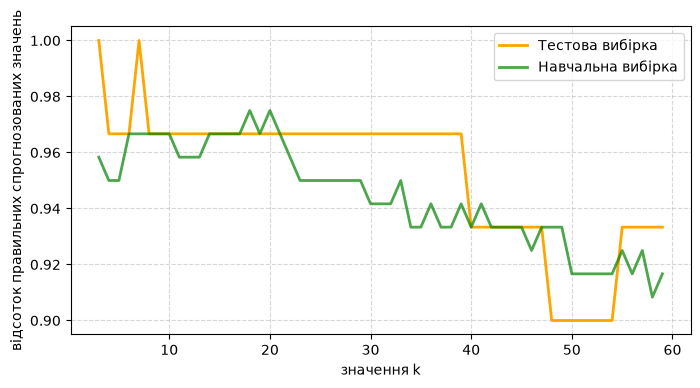

Максимальне значення точності для k-nn класифікатора = 1.0 при k = 3


In [50]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(K, qualityS, color='orange', linestyle='-', linewidth=2,  label='Тестова вибірка')
plt.plot(K, qualitySL, color='green', linestyle='-', alpha=0.7, linewidth=2, label='Навчальна вибірка')

plt.xlabel("значення k")
plt.ylabel("відсоток правильних спрогнозованих значень")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

print(f"Максимальне значення точності для k-nn класифікатора = {max(qualityS)} при k = {K[qualityS.index(max(qualityS))]}")

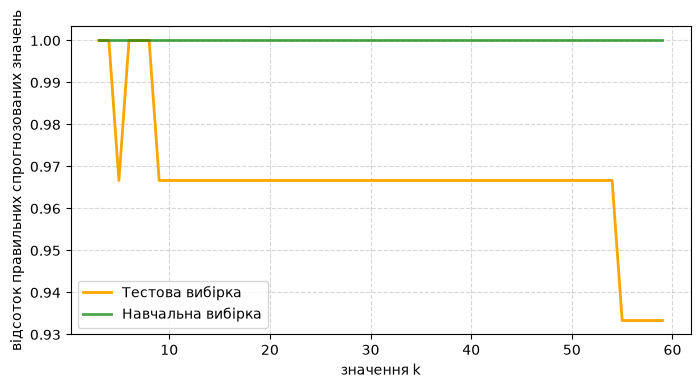

Максимальне значення точності для вагового k-nn класифікатора = 1.0 при k = 3


In [51]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(K, qualityW, color='orange', linestyle='-', linewidth=2, label='Тестова вибірка')
plt.plot(K, qualityWL, color='green', linestyle='-', alpha=0.7, linewidth=2, label='Навчальна вибірка')

plt.xlabel("значення k")
plt.ylabel("відсоток правильних спрогнозованих значень")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

print(f"Максимальне значення точності для вагового k-nn класифікатора = {max(qualityW)} при k = {K[qualityW.index(max(qualityW))]}")